# Tree Species Classification Using Transfer Learning

## Neural Networks for Computer Vision - Group Project

### Group Information

Group Name: `DILIVI`

Team Members:

1. Dmytro Krempovskyy
2. Vindya Nukulasooriya
3. Lien Pham
4. Dan Le

### Project Objective

The aim of this project is to classify urban street tree images into **23 tree species** using deep learning and transfer learning with PyTorch.

The project includes:
- Dataset exploration and preprocessing
- Data augmentation
- Transfer learning using **ResNet18 and ResNet34**
- Model training and validation
- Final evaluation using accuracy, precision, recall, F1-score, and confusion matrices
- Top-N classification analysis
- Comparison and improvement of the models

# 1. Dataset Exploration

Before training the models, the dataset was examined to understand its structure, class distribution, image properties, and possible data-quality issues.

The dataset is already divided into **training, validation, and test sets** and contains images from **23 tree species**.

In this section, we examine:
- Dataset structure and number of images
- Class distribution and imbalance
- Image dimensions and orientations
- Example images
- Corrupted or unreadable images
- Duplicate and potential data-quality issues

The purpose of this analysis is to make informed preprocessing decisions before training the ResNet models.

### Step 1 - Imports + environment check

In [2]:
from pathlib import Path
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

print("PyTorch version:", torch.__version__)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")

PyTorch version: 2.14.0+cpu
Device: cpu


### Step 2 - Dataset location and structure

The original dataset is kept separate from the GitHub repository because the image files are large and should not be committed to GitHub.

The dataset contains predefined `train`, `val`, and `test` splits.  
Each split contains one folder for each tree species.

### Step 3 - Portable dataset path

In [3]:
# Change this path if the dataset is stored in a different location.
DATA_DIR = Path(
    r"D:\HAMK\Year 3\Module 1\Neural Networks for Computer Vision\Project\Data\archive\tree"
)

train_dir = DATA_DIR / "train"
val_dir = DATA_DIR / "val"
test_dir = DATA_DIR / "test"

print("Dataset found:", DATA_DIR.exists())
print("Train folder:", train_dir.exists())
print("Validation folder:", val_dir.exists())
print("Test folder:", test_dir.exists())

Dataset found: True
Train folder: True
Validation folder: True
Test folder: True


### Step 4 - Verify dataset structure and counts

In [4]:
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def count_images(folder):
    return sum(
        1 for file in folder.rglob("*")
        if file.is_file() and file.suffix.lower() in image_extensions
    )

train_classes = sorted([p.name for p in train_dir.iterdir() if p.is_dir()])
val_classes = sorted([p.name for p in val_dir.iterdir() if p.is_dir()])
test_classes = sorted([p.name for p in test_dir.iterdir() if p.is_dir()])

train_count = count_images(train_dir)
val_count = count_images(val_dir)
test_count = count_images(test_dir)

print("Number of classes:", len(train_classes))
print("Same classes in all splits:", train_classes == val_classes == test_classes)
print()
print("Training images:", train_count)
print("Validation images:", val_count)
print("Test images:", test_count)
print("Total images:", train_count + val_count + test_count)

Number of classes: 23
Same classes in all splits: True

Training images: 3850
Validation images: 482
Test images: 472
Total images: 4804


### Step 5 - Class distribution

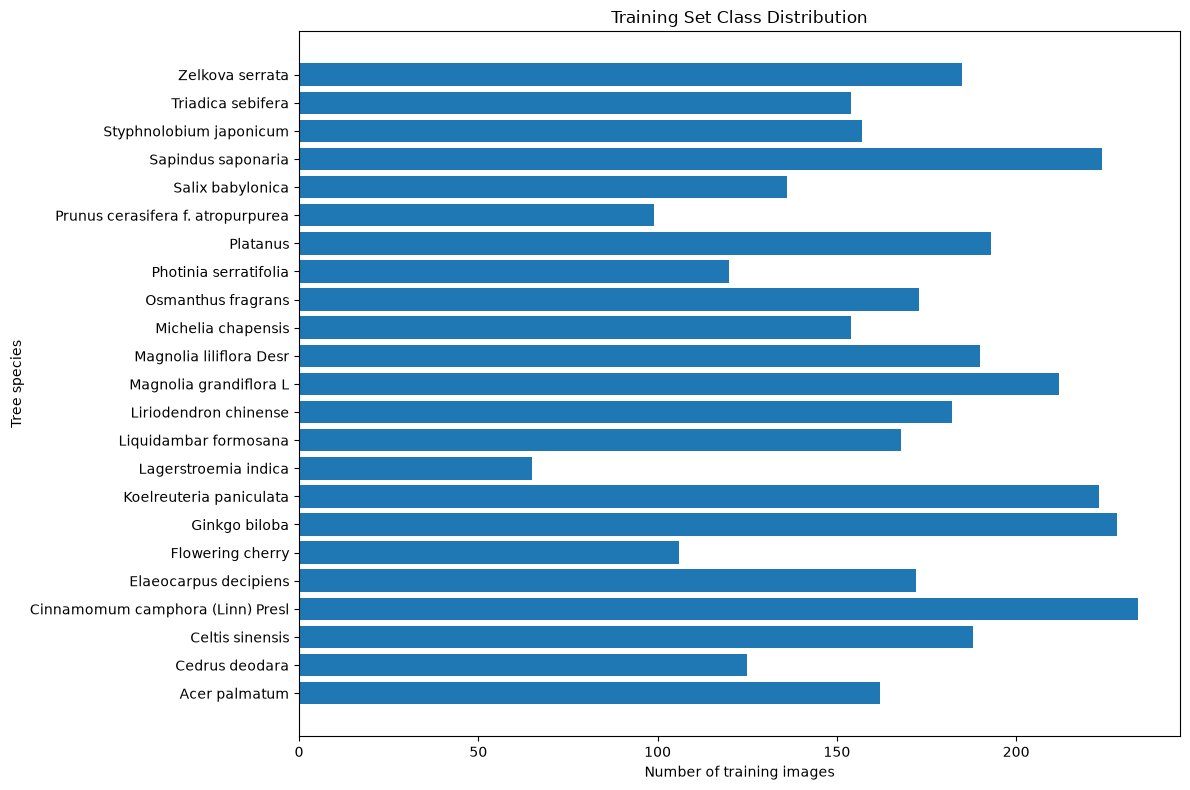

Largest class: Cinnamomum camphora (Linn) Presl (234 images)
Smallest class: Lagerstroemia indica (65 images)
Imbalance ratio: 3.60x


In [5]:
class_counts = {
    class_name: count_images(train_dir / class_name)
    for class_name in train_classes
}

plt.figure(figsize=(12, 8))
plt.barh(list(class_counts.keys()), list(class_counts.values()))
plt.xlabel("Number of training images")
plt.ylabel("Tree species")
plt.title("Training Set Class Distribution")
plt.tight_layout()
plt.show()

largest_class = max(class_counts, key=class_counts.get)
smallest_class = min(class_counts, key=class_counts.get)

print(f"Largest class: {largest_class} ({class_counts[largest_class]} images)")
print(f"Smallest class: {smallest_class} ({class_counts[smallest_class]} images)")
print(f"Imbalance ratio: {class_counts[largest_class] / class_counts[smallest_class]:.2f}x")

### Step 6 - Explain the finding

#### Class Distribution Observation

The training set is moderately imbalanced. The largest class contains **234 images**, while the smallest contains **65 images**, giving an imbalance ratio of approximately **3.6:1**.

Because the classes are not equally represented, model performance will not be evaluated using accuracy alone. **Precision, recall, F1-score, and confusion matrices** will also be used to examine performance across individual tree species.

### Step 7 - Examine image dimensions and orientation

In [6]:
dimension_counts = Counter()
portrait = 0
landscape = 0
square = 0

for class_name in train_classes:
    class_dir = train_dir / class_name

    for image_path in class_dir.iterdir():
        if image_path.suffix.lower() in image_extensions:
            with Image.open(image_path) as img:
                width, height = img.size
                dimension_counts[(width, height)] += 1

                if height > width:
                    portrait += 1
                elif width > height:
                    landscape += 1
                else:
                    square += 1

print("Unique image dimensions:", len(dimension_counts))
print("Portrait images:", portrait)
print("Landscape images:", landscape)
print("Square images:", square)

print("\nMost common dimensions:")
for size, count in dimension_counts.most_common(10):
    print(f"{size}: {count} images")

Unique image dimensions: 63
Portrait images: 243
Landscape images: 3607
Square images: 0

Most common dimensions:
(1600, 1200): 3602 images
(1200, 1600): 163 images
(1199, 1600): 20 images
(1283, 1600): 2 images
(973, 1600): 2 images
(1350, 1600): 2 images
(1275, 1600): 2 images
(1133, 1600): 2 images
(1250, 1600): 1 images
(1404, 1600): 1 images


### Step 8 - Interpretation

#### Image Size and Orientation Observation

The training images have **63 different dimensions**, although most images (3,602) are **1600 × 1200** pixels.

The dataset contains **3,607 landscape images** and **243 portrait images**. This variation means that the model preprocessing must convert images to a consistent input size while handling different orientations.

For the ResNet models, all images will therefore be transformed to a standard **224 × 224** model input. Training-time augmentation will also be used to improve robustness to natural variations in the images.

### Step 9 - Visualize example images

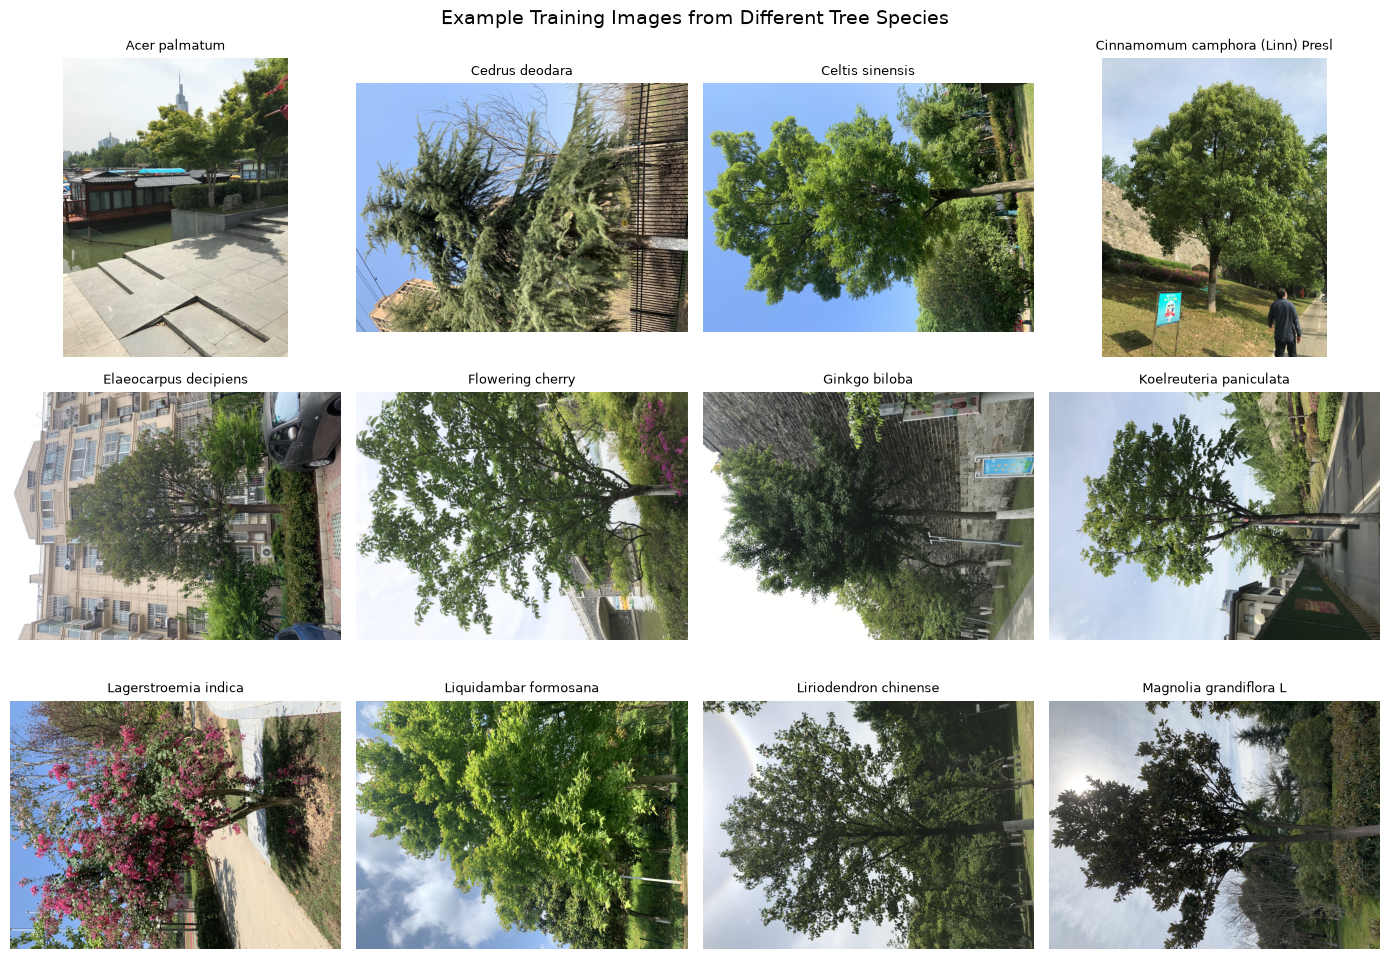

In [7]:
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
axes = axes.flatten()

# Show examples from 12 different classes
selected_classes = train_classes[:12]

for ax, class_name in zip(axes, selected_classes):
    class_dir = train_dir / class_name

    image_paths = [
        p for p in class_dir.iterdir()
        if p.suffix.lower() in image_extensions
    ]

    image_path = image_paths[0]

    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(class_name, fontsize=9)
    ax.axis("off")

plt.suptitle("Example Training Images from Different Tree Species", fontsize=14)
plt.tight_layout()
plt.show()

### Step 10 - data quality checks

In [8]:
corrupted_files = []

for split_name, split_dir in {
    "train": train_dir,
    "val": val_dir,
    "test": test_dir
}.items():

    for image_path in split_dir.rglob("*"):
        if image_path.is_file() and image_path.suffix.lower() in image_extensions:
            try:
                with Image.open(image_path) as img:
                    img.verify()
            except Exception:
                corrupted_files.append((split_name, str(image_path)))

print("Corrupted or unreadable images:", len(corrupted_files))

if corrupted_files:
    for split_name, path in corrupted_files[:10]:
        print(split_name, path)
else:
    print("No corrupted or unreadable images were found.")

Corrupted or unreadable images: 0
No corrupted or unreadable images were found.


### Dataset Exploration Summary

The dataset contains **4,804 images from 23 tree species**, divided into predefined training, validation, and test sets.

The exploration showed that:

- All three splits contain the same 23 classes.
- The training set is moderately imbalanced, with an approximately **3.6:1** ratio between the largest and smallest classes.
- Images have different dimensions and orientations, although most are landscape images of **1600 × 1200** pixels.
- Visual inspection shows variation in orientation, viewpoint, background, lighting, and tree appearance.
- No corrupted or unreadable images were found.

These observations will guide the preprocessing and augmentation strategy used for the ResNet models.

# 2. Data Preprocessing and Augmentation

The images must be transformed into a consistent format before they can be used with the pretrained ResNet models.

The same preprocessing strategy will be used for **ResNet18 and ResNet34** to allow a fair comparison between the two models.

For the training set, data augmentation is used to introduce realistic variation and help reduce overfitting. Validation and test images use deterministic preprocessing without random augmentation.

The preprocessing pipeline includes:
- Converting images to RGB
- Resizing/cropping images to **224 × 224**
- Random augmentation for training images only
- Converting images to PyTorch tensors
- Normalizing using **ImageNet mean and standard deviation**

### Step 11 - Define image transforms

In [13]:
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

# Training: preprocessing + augmentation
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        224,
        scale=(0.80, 1.00),
        ratio=(0.90, 1.10)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10, fill=(128, 128, 128)),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10,
        hue=0.02
    ),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

# Validation/test: deterministic preprocessing only
eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

print("Training transform:")
print(train_transform)

print("\nValidation/Test transform:")
print(eval_transform)

Training transform:
Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.8, 1.0), ratio=(0.9, 1.1), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=(128, 128, 128))
    ColorJitter(brightness=(0.85, 1.15), contrast=(0.85, 1.15), saturation=(0.9, 1.1), hue=(-0.02, 0.02))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Validation/Test transform:
Compose(
    Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


### Step 12 - Create the datasets

In [14]:
train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    val_dir,
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=eval_transform
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))
print("Number of classes:", len(train_dataset.classes))
print("Same class mapping:", 
      train_dataset.class_to_idx == val_dataset.class_to_idx == test_dataset.class_to_idx)

Training samples: 3850
Validation samples: 482
Test samples: 472
Number of classes: 23
Same class mapping: True


### Step 13 - Create DataLoaders

In [15]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Batch size:", BATCH_SIZE)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

images, labels = next(iter(train_loader))

print("\nImage batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Batch size: 32
Training batches: 121
Validation batches: 16
Test batches: 15

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])


### Step 14 - Visualize the training augmentation

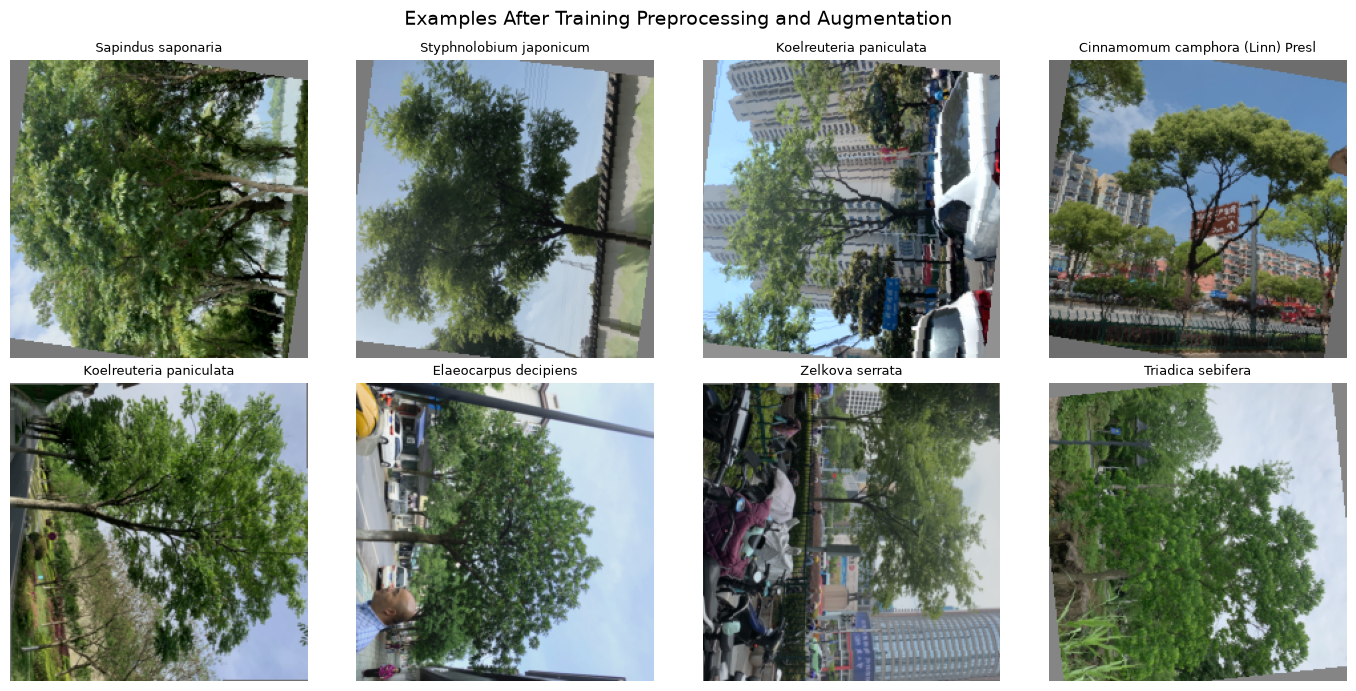

In [16]:
# ImageNet values as tensors for reversing normalization
mean = torch.tensor(imagenet_mean).view(3, 1, 1)
std = torch.tensor(imagenet_std).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

for i in range(8):
    image = images[i] * std + mean
    image = torch.clamp(image, 0, 1)

    axes[i].imshow(image.permute(1, 2, 0))
    axes[i].set_title(train_dataset.classes[labels[i].item()], fontsize=9)
    axes[i].axis("off")

plt.suptitle("Examples After Training Preprocessing and Augmentation", fontsize=14)
plt.tight_layout()
plt.show()

### Step 15 - Preprocessing and Augmentation Summary

A common preprocessing pipeline was prepared for both **ResNet18 and ResNet34** to ensure a fair model comparison.

For training images, mild augmentation is applied using random resized cropping, horizontal flipping, rotation (±10°), and color jitter. These transformations introduce realistic variation and help reduce overfitting.

Validation and test images are processed deterministically using resizing and center cropping, without random augmentation.

All images are converted to **224 × 224 RGB tensors** and normalized using the **ImageNet mean and standard deviation**, matching the preprocessing expected by the pretrained ResNet models.

The final DataLoaders use a batch size of **32**, with shuffling enabled only for the training set.

# 3. ResNet18 Transfer Learning

The first model evaluated in this project is **ResNet18**, pretrained on the ImageNet dataset.

Transfer learning allows the model to reuse visual features learned from a large image dataset instead of learning all features from scratch.

For this experiment, the pretrained ResNet18 model will be adapted to classify the **23 tree species** in our dataset.

To establish a clear baseline, the pretrained feature-extraction layers will first be **frozen**, and only the final classification layer will be trained. The final fully connected layer is replaced so that the model produces **23 output logits**, one for each tree species.

The performance of this baseline model will later be compared with ResNet34 and with model-improvement experiments.

### Step 16 - Create pretrained ResNet18 model

In [17]:
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

resnet18 = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Freeze all pretrained layers
for param in resnet18.parameters():
    param.requires_grad = False

# Replace the final classification layer
num_features = resnet18.fc.in_features
resnet18.fc = nn.Linear(num_features, len(train_dataset.classes))

resnet18 = resnet18.to(device)

print("Device:", device)
print("Original FC input features:", num_features)
print("Number of output classes:", resnet18.fc.out_features)

trainable_params = sum(
    p.numel() for p in resnet18.parameters() if p.requires_grad
)

total_params = sum(p.numel() for p in resnet18.parameters())

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Device: cpu
Original FC input features: 512
Number of output classes: 23
Total parameters: 11188311
Trainable parameters: 11799


### Step 17 - Define loss function and optimizer

In [18]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    resnet18.fc.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])

Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001


### Step 18 - Define training and validation function

In [19]:
import copy
import time

def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=10):
    best_val_acc = 0.0
    best_model_state = copy.deepcopy(model.state_dict())

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    for epoch in range(epochs):
        start_time = time.time()

        # ----- Training -----
        model.train()

        running_loss = 0.0
        running_correct = 0
        running_total = 0

        for inputs, labels in train_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)

            predictions = outputs.argmax(dim=1)
            running_correct += (predictions == labels).sum().item()
            running_total += labels.size(0)

        train_loss = running_loss / running_total
        train_acc = running_correct / running_total

        # ----- Validation -----
        model.eval()

        val_loss_sum = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs = inputs.to(device)
                labels = labels.to(device)

                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss_sum += loss.item() * inputs.size(0)

                predictions = outputs.argmax(dim=1)
                val_correct += (predictions == labels).sum().item()
                val_total += labels.size(0)

        val_loss = val_loss_sum / val_total
        val_acc = val_correct / val_total

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        # Keep the best validation model
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model_state = copy.deepcopy(model.state_dict())

        elapsed = time.time() - start_time

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.3f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.3f} | "
            f"Time: {elapsed:.1f}s"
        )

    # Restore best validation model
    model.load_state_dict(best_model_state)

    print(f"\nBest validation accuracy: {best_val_acc:.3f}")

    return model, history

### Step 19 - Train ResNet18 baseline

In [20]:
EPOCHS = 10

resnet18, resnet18_history = train_model(
    resnet18,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs=EPOCHS
)

Epoch 1/10 | Train Loss: 2.7560 | Train Acc: 0.200 | Val Loss: 2.2092 | Val Acc: 0.421 | Time: 267.9s
Epoch 2/10 | Train Loss: 2.1115 | Train Acc: 0.436 | Val Loss: 1.7924 | Val Acc: 0.519 | Time: 259.0s
Epoch 3/10 | Train Loss: 1.8171 | Train Acc: 0.501 | Val Loss: 1.6538 | Val Acc: 0.523 | Time: 257.2s
Epoch 4/10 | Train Loss: 1.6392 | Train Acc: 0.550 | Val Loss: 1.5636 | Val Acc: 0.546 | Time: 249.7s
Epoch 5/10 | Train Loss: 1.5473 | Train Acc: 0.567 | Val Loss: 1.4577 | Val Acc: 0.579 | Time: 240.9s
Epoch 6/10 | Train Loss: 1.4501 | Train Acc: 0.585 | Val Loss: 1.4029 | Val Acc: 0.606 | Time: 249.5s
Epoch 7/10 | Train Loss: 1.3893 | Train Acc: 0.611 | Val Loss: 1.3452 | Val Acc: 0.602 | Time: 255.5s
Epoch 8/10 | Train Loss: 1.3350 | Train Acc: 0.623 | Val Loss: 1.3596 | Val Acc: 0.606 | Time: 240.1s
Epoch 9/10 | Train Loss: 1.3052 | Train Acc: 0.626 | Val Loss: 1.2765 | Val Acc: 0.647 | Time: 239.2s
Epoch 10/10 | Train Loss: 1.2396 | Train Acc: 0.645 | Val Loss: 1.2810 | Val Acc: 

### Step 20 - Evaluate ResNet18 on the test set

In [21]:
resnet18.eval()

test_loss_sum = 0.0
test_correct = 0
test_total = 0

y_true_resnet18 = []
y_pred_resnet18 = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = resnet18(inputs)
        loss = criterion(outputs, labels)

        test_loss_sum += loss.item() * inputs.size(0)

        predictions = outputs.argmax(dim=1)

        test_correct += (predictions == labels).sum().item()
        test_total += labels.size(0)

        y_true_resnet18.extend(labels.cpu().numpy())
        y_pred_resnet18.extend(predictions.cpu().numpy())

resnet18_test_loss = test_loss_sum / test_total
resnet18_test_acc = test_correct / test_total

print(f"ResNet18 Test Loss: {resnet18_test_loss:.4f}")
print(f"ResNet18 Test Accuracy: {resnet18_test_acc:.3f}")
print(f"Correct predictions: {test_correct}/{test_total}")

ResNet18 Test Loss: 1.5135
ResNet18 Test Accuracy: 0.559
Correct predictions: 264/472


### Step 21 - Precision, Recall and F1

In [22]:
# Step 21 - ResNet18 classification metrics

from sklearn.metrics import precision_score, recall_score, f1_score

resnet18_precision = precision_score(
    y_true_resnet18,
    y_pred_resnet18,
    average="macro",
    zero_division=0
)

resnet18_recall = recall_score(
    y_true_resnet18,
    y_pred_resnet18,
    average="macro",
    zero_division=0
)

resnet18_f1 = f1_score(
    y_true_resnet18,
    y_pred_resnet18,
    average="macro",
    zero_division=0
)

print(f"ResNet18 Accuracy:  {resnet18_test_acc:.3f}")
print(f"ResNet18 Precision: {resnet18_precision:.3f}")
print(f"ResNet18 Recall:    {resnet18_recall:.3f}")
print(f"ResNet18 F1-score:  {resnet18_f1:.3f}")

ResNet18 Accuracy:  0.559
ResNet18 Precision: 0.617
ResNet18 Recall:    0.575
ResNet18 F1-score:  0.575


### Step 22 - ResNet18 Confusion Matrix

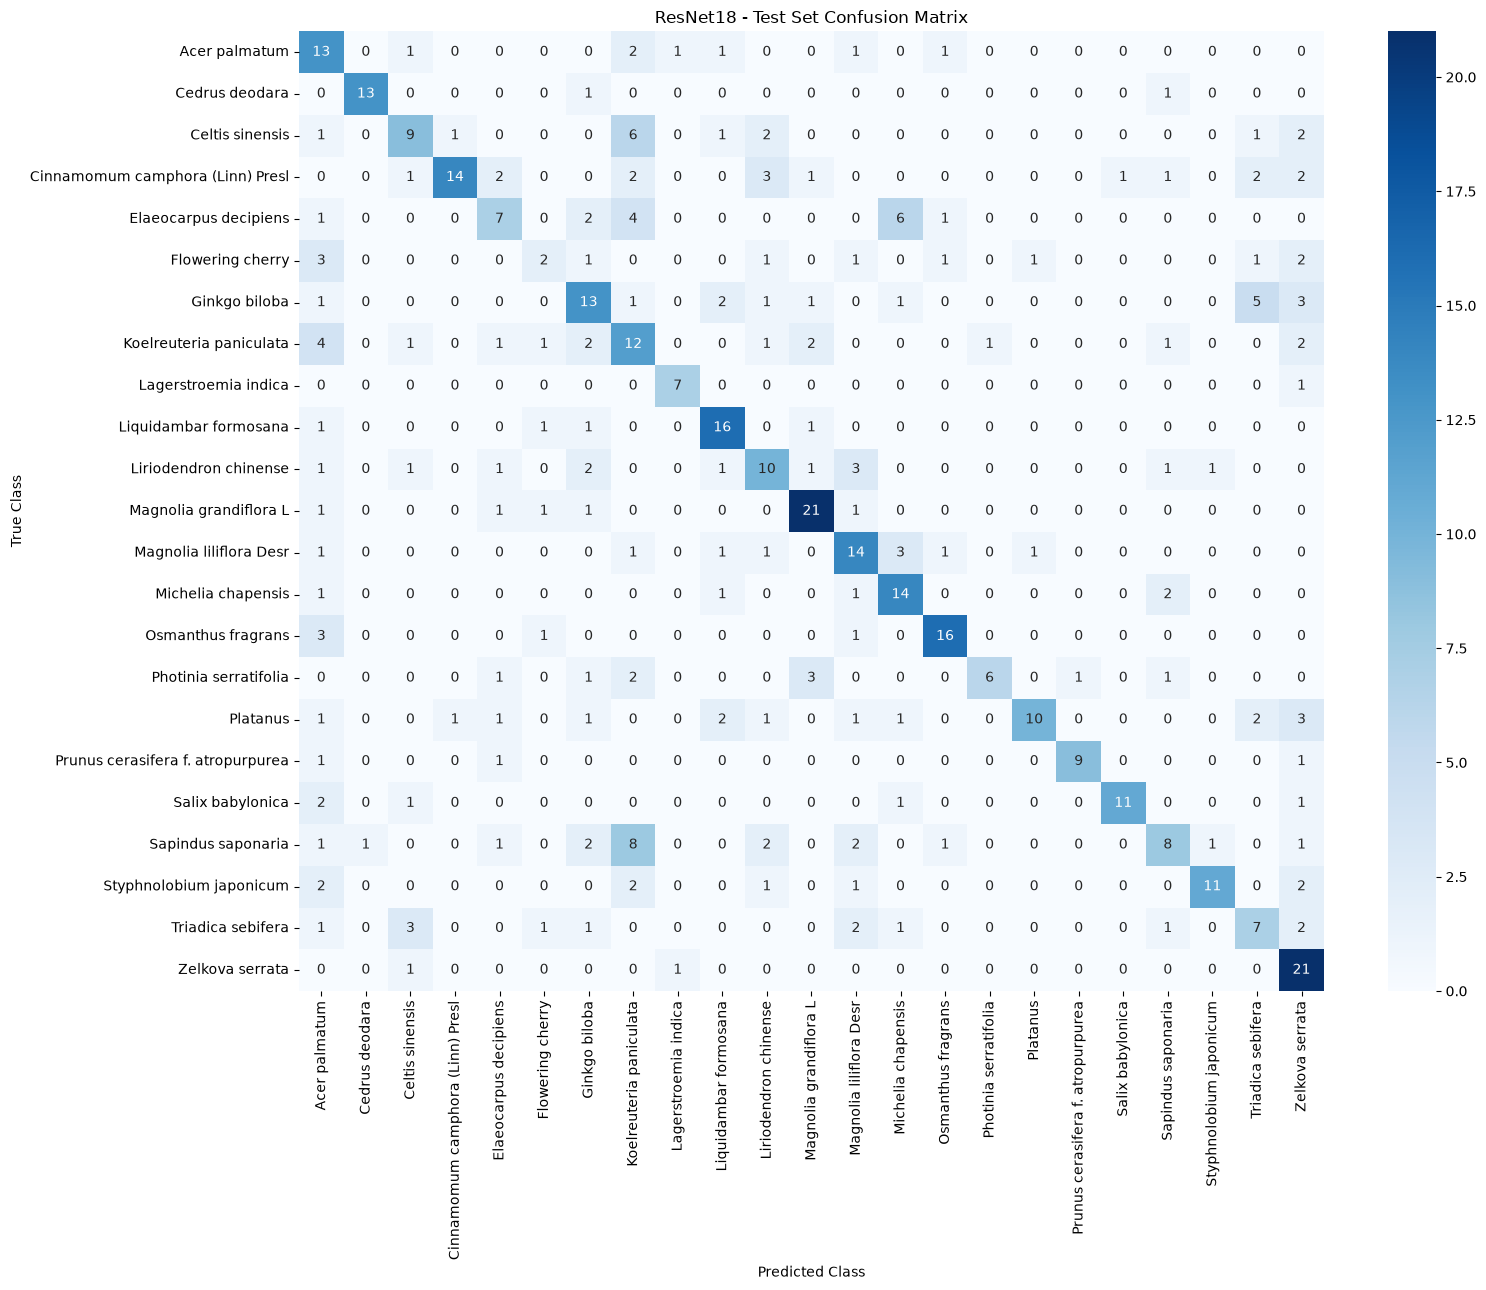

In [23]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm_resnet18 = confusion_matrix(
    y_true_resnet18,
    y_pred_resnet18
)

plt.figure(figsize=(16, 13))

sns.heatmap(
    cm_resnet18,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=train_dataset.classes,
    yticklabels=train_dataset.classes
)

plt.title("ResNet18 - Test Set Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Step 23 - ResNet18 Top-N Accuracy

In [24]:
resnet18.eval()

top_n_correct = {n: 0 for n in range(1, 6)}
total = 0

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = resnet18(inputs)

        # Get the 5 highest-scoring predicted classes
        _, top5_predictions = outputs.topk(5, dim=1)

        total += labels.size(0)

        for n in range(1, 6):
            correct = top5_predictions[:, :n].eq(
                labels.view(-1, 1)
            ).any(dim=1)

            top_n_correct[n] += correct.sum().item()

resnet18_topn = {}

for n in range(1, 6):
    accuracy = top_n_correct[n] / total
    resnet18_topn[n] = accuracy

    print(f"ResNet18 Top-{n} Accuracy: {accuracy:.3f} ({accuracy*100:.1f}%)")

ResNet18 Top-1 Accuracy: 0.559 (55.9%)
ResNet18 Top-2 Accuracy: 0.686 (68.6%)
ResNet18 Top-3 Accuracy: 0.769 (76.9%)
ResNet18 Top-4 Accuracy: 0.822 (82.2%)
ResNet18 Top-5 Accuracy: 0.850 (85.0%)


### Step 24 - ResNet18 Results Summary

The pretrained ResNet18 feature extractor was frozen, and only the new final classification layer was trained for 10 epochs.

The best validation accuracy was **64.7%**, achieved at epoch 9. The weights from this best validation epoch were restored before final testing.

On the independent test set, ResNet18 achieved:

- **Accuracy:** 55.9% (264/472 correct)
- **Macro Precision:** 0.617
- **Macro Recall:** 0.575
- **Macro F1-score:** 0.575
- **Top-2 Accuracy:** 68.6%
- **Top-3 Accuracy:** 76.9%
- **Top-4 Accuracy:** 82.2%
- **Top-5 Accuracy:** 85.0%

The difference between validation accuracy (64.7%) and test accuracy (55.9%) indicates weaker generalization to the unseen test set. However, the Top-N results show that the correct tree species was often among the model's highest-ranked alternatives even when the Top-1 prediction was incorrect.

These results provide the baseline for comparison with the larger ResNet34 model.

# 4. ResNet34 Transfer Learning

The second model evaluated in this project is **ResNet34**, a deeper ResNet architecture than ResNet18.

To make the comparison between the two models fair, ResNet34 uses the same:

- Training, validation, and test splits
- Image preprocessing and augmentation
- Batch size
- Transfer-learning strategy
- Loss function and optimizer settings
- Number of training epochs
- Evaluation metrics

As with the ResNet18 baseline, the pretrained ResNet34 feature-extraction layers are initially **frozen**, and only the final classification layer is trained. The original final layer is replaced with a new layer producing **23 output logits**, one for each tree species.

This controlled experiment allows us to investigate whether the larger ResNet34 architecture improves classification performance under the same training conditions.

### Step 25 - Create pretrained ResNet34 model

In [25]:
resnet34 = models.resnet34(
    weights=models.ResNet34_Weights.DEFAULT
)

# Freeze all pretrained layers
for param in resnet34.parameters():
    param.requires_grad = False

# Replace the final classification layer
num_features_34 = resnet34.fc.in_features
resnet34.fc = nn.Linear(
    num_features_34,
    len(train_dataset.classes)
)

resnet34 = resnet34.to(device)

# Count parameters
trainable_params_34 = sum(
    p.numel() for p in resnet34.parameters() if p.requires_grad
)

total_params_34 = sum(
    p.numel() for p in resnet34.parameters()
)

print("Device:", device)
print("Original FC input features:", num_features_34)
print("Number of output classes:", resnet34.fc.out_features)
print("Total parameters:", total_params_34)
print("Trainable parameters:", trainable_params_34)

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to C:\Users\Vindy Suba/.cache\torch\hub\checkpoints\resnet34-b627a593.pth


100.0%


Device: cpu
Original FC input features: 512
Number of output classes: 23
Total parameters: 21296471
Trainable parameters: 11799


### Step 26 - Define loss function and optimizer for ResNet34

In [26]:
criterion_34 = nn.CrossEntropyLoss()

optimizer_34 = optim.Adam(
    resnet34.fc.parameters(),
    lr=0.001
)

print("Loss function:", criterion_34)
print("Optimizer:", optimizer_34.__class__.__name__)
print("Learning rate:", optimizer_34.param_groups[0]["lr"])

Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001


### Step 27 - Train ResNet34 baseline

In [27]:
EPOCHS_34 = 10

resnet34, resnet34_history = train_model(
    resnet34,
    train_loader,
    val_loader,
    criterion_34,
    optimizer_34,
    epochs=EPOCHS_34
)

Epoch 1/10 | Train Loss: 2.7610 | Train Acc: 0.206 | Val Loss: 2.2416 | Val Acc: 0.394 | Time: 351.9s
Epoch 2/10 | Train Loss: 2.0891 | Train Acc: 0.433 | Val Loss: 1.8636 | Val Acc: 0.504 | Time: 339.0s
Epoch 3/10 | Train Loss: 1.7918 | Train Acc: 0.509 | Val Loss: 1.6541 | Val Acc: 0.535 | Time: 333.2s
Epoch 4/10 | Train Loss: 1.6311 | Train Acc: 0.542 | Val Loss: 1.5423 | Val Acc: 0.552 | Time: 346.9s
Epoch 5/10 | Train Loss: 1.5093 | Train Acc: 0.575 | Val Loss: 1.4925 | Val Acc: 0.548 | Time: 342.4s
Epoch 6/10 | Train Loss: 1.4293 | Train Acc: 0.582 | Val Loss: 1.3798 | Val Acc: 0.595 | Time: 342.5s
Epoch 7/10 | Train Loss: 1.3783 | Train Acc: 0.604 | Val Loss: 1.3588 | Val Acc: 0.587 | Time: 323.9s
Epoch 8/10 | Train Loss: 1.3142 | Train Acc: 0.612 | Val Loss: 1.2961 | Val Acc: 0.620 | Time: 327.6s
Epoch 9/10 | Train Loss: 1.2740 | Train Acc: 0.623 | Val Loss: 1.3127 | Val Acc: 0.610 | Time: 322.8s
Epoch 10/10 | Train Loss: 1.2330 | Train Acc: 0.640 | Val Loss: 1.2540 | Val Acc: 

### Step 28 - Evaluate ResNet34 on the test set

In [28]:
resnet34.eval()

test_loss_sum_34 = 0.0
test_correct_34 = 0
test_total_34 = 0

y_true_resnet34 = []
y_pred_resnet34 = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = resnet34(inputs)
        loss = criterion_34(outputs, labels)

        test_loss_sum_34 += loss.item() * inputs.size(0)

        predictions = outputs.argmax(dim=1)

        test_correct_34 += (predictions == labels).sum().item()
        test_total_34 += labels.size(0)

        y_true_resnet34.extend(labels.cpu().numpy())
        y_pred_resnet34.extend(predictions.cpu().numpy())

resnet34_test_loss = test_loss_sum_34 / test_total_34
resnet34_test_acc = test_correct_34 / test_total_34

print(f"ResNet34 Test Loss: {resnet34_test_loss:.4f}")
print(f"ResNet34 Test Accuracy: {resnet34_test_acc:.3f}")
print(f"Correct predictions: {test_correct_34}/{test_total_34}")

ResNet34 Test Loss: 1.5424
ResNet34 Test Accuracy: 0.542
Correct predictions: 256/472


### Step 29 - Precision, Recall and F1

In [29]:
# Step 29 - ResNet34 classification metrics

resnet34_precision = precision_score(
    y_true_resnet34,
    y_pred_resnet34,
    average="macro",
    zero_division=0
)

resnet34_recall = recall_score(
    y_true_resnet34,
    y_pred_resnet34,
    average="macro",
    zero_division=0
)

resnet34_f1 = f1_score(
    y_true_resnet34,
    y_pred_resnet34,
    average="macro",
    zero_division=0
)

print(f"ResNet34 Accuracy:  {resnet34_test_acc:.3f}")
print(f"ResNet34 Precision: {resnet34_precision:.3f}")
print(f"ResNet34 Recall:    {resnet34_recall:.3f}")
print(f"ResNet34 F1-score:  {resnet34_f1:.3f}")

ResNet34 Accuracy:  0.542
ResNet34 Precision: 0.589
ResNet34 Recall:    0.551
ResNet34 F1-score:  0.555


### Step 30 - ResNet34 Confusion Matrix

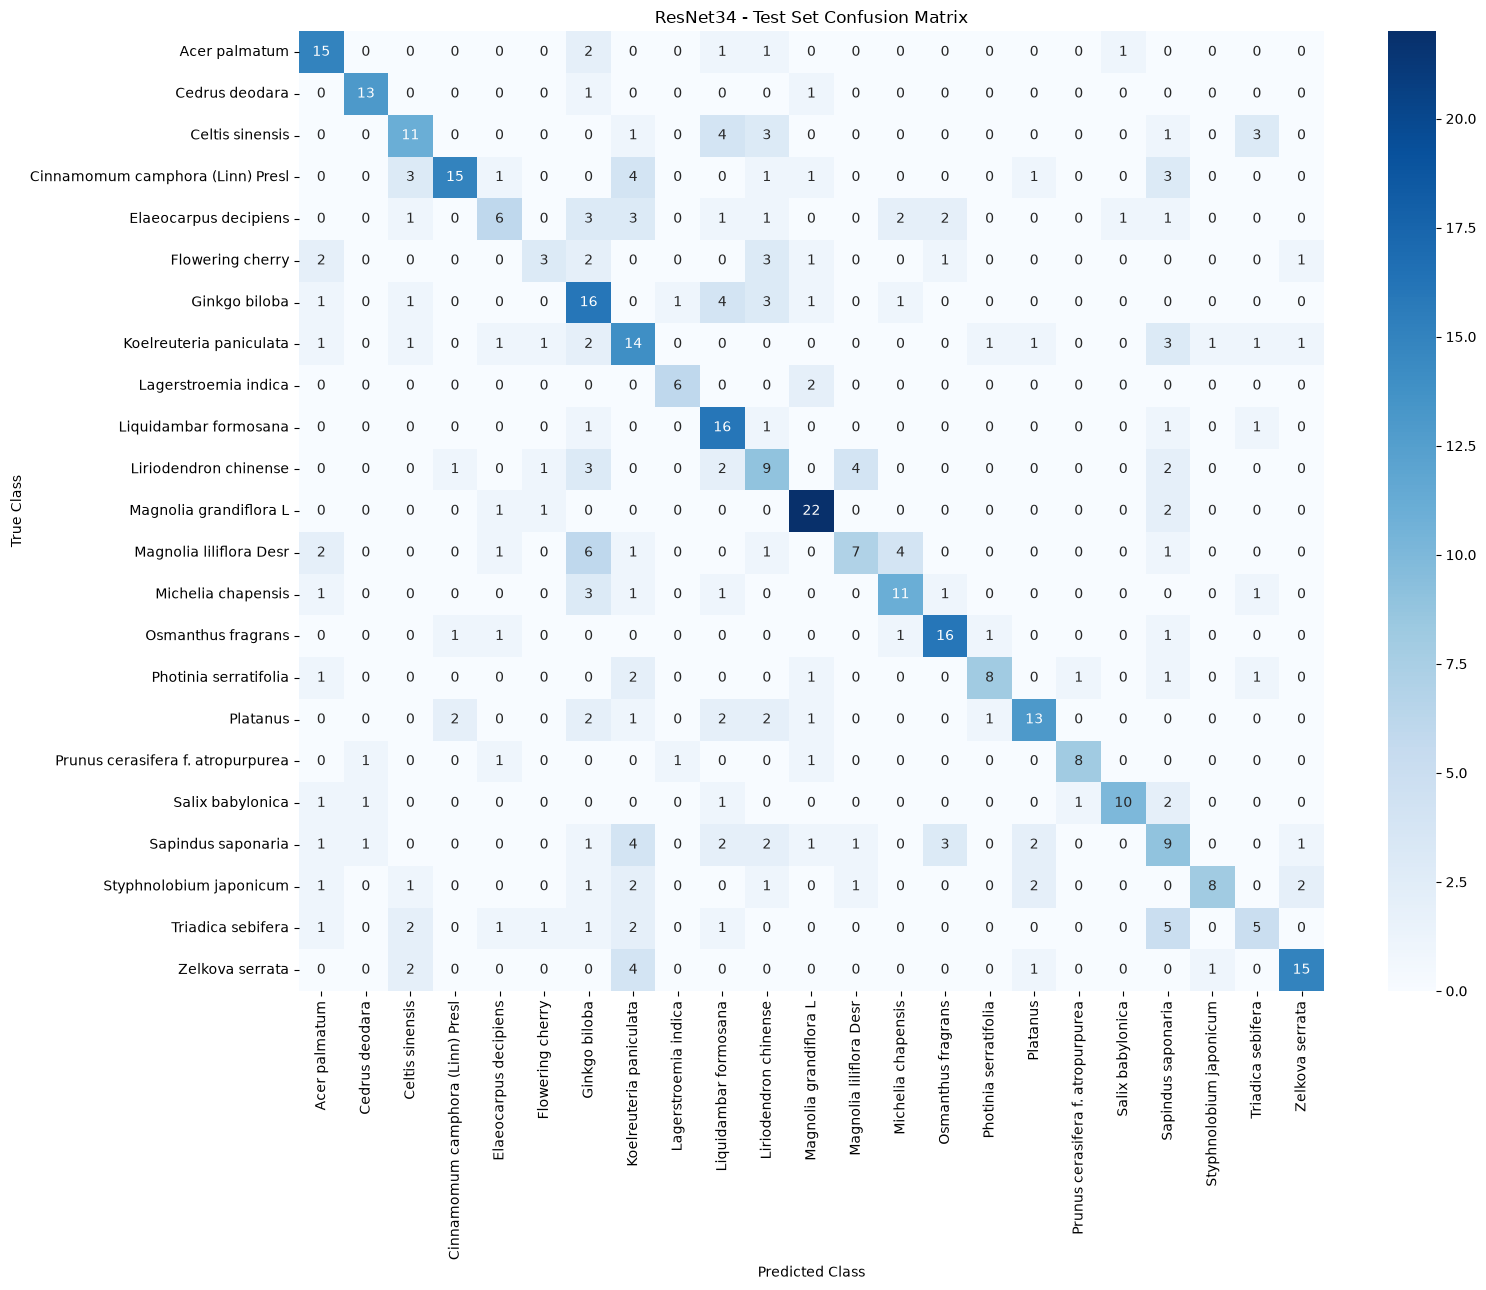

In [30]:
cm_resnet34 = confusion_matrix(
    y_true_resnet34,
    y_pred_resnet34
)

plt.figure(figsize=(16, 13))

sns.heatmap(
    cm_resnet34,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=train_dataset.classes,
    yticklabels=train_dataset.classes
)

plt.title("ResNet34 - Test Set Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Step 31 - ResNet34 Top-N Accuracy

In [31]:
resnet34.eval()

top_n_correct_34 = {n: 0 for n in range(1, 6)}
total_34 = 0

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = resnet34(inputs)

        _, top5_predictions = outputs.topk(5, dim=1)

        total_34 += labels.size(0)

        for n in range(1, 6):
            correct = top5_predictions[:, :n].eq(
                labels.view(-1, 1)
            ).any(dim=1)

            top_n_correct_34[n] += correct.sum().item()

resnet34_topn = {}

for n in range(1, 6):
    accuracy = top_n_correct_34[n] / total_34
    resnet34_topn[n] = accuracy

    print(f"ResNet34 Top-{n} Accuracy: {accuracy:.3f} ({accuracy*100:.1f}%)")

ResNet34 Top-1 Accuracy: 0.542 (54.2%)
ResNet34 Top-2 Accuracy: 0.669 (66.9%)
ResNet34 Top-3 Accuracy: 0.756 (75.6%)
ResNet34 Top-4 Accuracy: 0.807 (80.7%)
ResNet34 Top-5 Accuracy: 0.850 (85.0%)


### Step 32 - ResNet34 Results Summary

The pretrained ResNet34 feature extractor was frozen, and only the new final classification layer was trained for 10 epochs.

The best validation accuracy was **63.3%**, achieved at epoch 10. The weights from this best validation epoch were used for final testing.

On the independent test set, ResNet34 achieved:

- **Accuracy:** 54.2% (256/472 correct)
- **Macro Precision:** 0.589
- **Macro Recall:** 0.551
- **Macro F1-score:** 0.555
- **Top-2 Accuracy:** 66.9%
- **Top-3 Accuracy:** 75.6%
- **Top-4 Accuracy:** 80.7%
- **Top-5 Accuracy:** 85.0%

The test accuracy (54.2%) was lower than the best validation accuracy (63.3%), indicating weaker generalization to the unseen test set. However, the Top-N results show that the correct tree species was frequently among the model's highest-ranked alternatives even when the Top-1 prediction was incorrect.

These results provide the ResNet34 baseline for direct comparison with the ResNet18 baseline under the same training conditions.

## Controlled Baseline Comparison: ResNet18 vs ResNet34

ResNet18 and ResNet34 were trained and evaluated under the same conditions to provide a fair comparison. Both models used the same dataset splits, preprocessing and augmentation, batch size, optimizer settings, number of epochs, and transfer-learning strategy. The pretrained feature-extraction layers were frozen, and only the final 23-class classification layer was trained.

| Metric | ResNet18 | ResNet34 |
|---|---:|---:|
| Best Validation Accuracy | 64.7% | 63.3% |
| Test Accuracy | 55.9% | 54.2% |
| Macro Precision | 0.617 | 0.589 |
| Macro Recall | 0.575 | 0.551 |
| Macro F1-score | 0.575 | 0.555 |
| Top-2 Accuracy | 68.6% | 66.9% |
| Top-3 Accuracy | 76.9% | 75.6% |
| Top-4 Accuracy | 82.2% | 80.7% |
| Top-5 Accuracy | 85.0% | 85.0% |

Under this frozen-feature baseline setup, the deeper ResNet34 did not improve the classification performance. ResNet18 achieved slightly higher test accuracy and macro-averaged precision, recall, and F1-score.

The Top-N results also show that both models often ranked the correct species among their highest-scoring alternatives even when the Top-1 prediction was incorrect.

These results suggest that simply increasing the depth of the ResNet architecture was not sufficient to improve performance under the current training strategy. Therefore, the next stage investigates changes to the training and data-processing approach to improve model performance.

# 5. Model Improvement

The controlled baseline experiments showed that training only the final classification layer resulted in relatively limited test performance for both ResNet18 and ResNet34.

Therefore, the next stage focuses on improving the ResNet34 model. The improvement experiments investigate whether changes to the training strategy and data preparation can help the pretrained network adapt more effectively to the tree-species classification task.

The improved model will be evaluated using the same main measures:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion matrix
- Top-N accuracy

The results will then be compared with the baseline models to determine how much the changes improved classification performance.

### Step 33 - Improved ResNet34: Full Fine-Tuning

The baseline ResNet34 trained only the final classification layer while keeping the pretrained feature extractor frozen. Its test accuracy was 54.2%.

To improve the model, the next experiment uses **full fine-tuning**. All layers of the pretrained ResNet34 are allowed to update so that the ImageNet features can adapt to the tree-species dataset.

Following the stronger ResNet34 experiment, the training configuration is changed to:

- Pretrained ResNet34
- All model parameters trainable
- CrossEntropyLoss
- SGD optimizer
- Learning rate = 0.001
- Momentum = 0.9
- StepLR scheduler with step size 7 and gamma 0.1
- 25 epochs
- Best validation model restored before final testing

This experiment tests whether adapting the complete pretrained network provides better performance than frozen feature extraction.

### Step 34 - Create the fully fine-tuned ResNet34

In [32]:
resnet34_ft = models.resnet34(
    weights=models.ResNet34_Weights.DEFAULT
)

# Replace the final layer for our 23 tree species
num_features = resnet34_ft.fc.in_features
resnet34_ft.fc = nn.Linear(num_features, len(train_dataset.classes))

# IMPORTANT:
# We do NOT freeze the pretrained layers.
# All layers will be trainable.
resnet34_ft = resnet34_ft.to(device)

total_params_ft = sum(p.numel() for p in resnet34_ft.parameters())
trainable_params_ft = sum(
    p.numel() for p in resnet34_ft.parameters()
    if p.requires_grad
)

print("Device:", device)
print("Number of output classes:", len(train_dataset.classes))
print("Total parameters:", total_params_ft)
print("Trainable parameters:", trainable_params_ft)
print("All parameters trainable:",
      total_params_ft == trainable_params_ft)

Device: cpu
Number of output classes: 23
Total parameters: 21296471
Trainable parameters: 21296471
All parameters trainable: True


### Step 35 - Loss, optimizer and learning-rate scheduler for full fine-tuning

In [33]:
criterion_ft = nn.CrossEntropyLoss()

optimizer_ft = torch.optim.SGD(
    resnet34_ft.parameters(),
    lr=0.001,
    momentum=0.9
)

scheduler_ft = torch.optim.lr_scheduler.StepLR(
    optimizer_ft,
    step_size=7,
    gamma=0.1
)

print("Loss function:", criterion_ft)
print("Optimizer:", optimizer_ft.__class__.__name__)
print("Initial learning rate:", optimizer_ft.param_groups[0]["lr"])
print("Momentum:", optimizer_ft.param_groups[0]["momentum"])
print("Scheduler:", scheduler_ft.__class__.__name__)
print("Scheduler step size:", scheduler_ft.step_size)
print("Scheduler gamma:", scheduler_ft.gamma)

Loss function: CrossEntropyLoss()
Optimizer: SGD
Initial learning rate: 0.001
Momentum: 0.9
Scheduler: StepLR
Scheduler step size: 7
Scheduler gamma: 0.1


### Step 36 - Training function with scheduler

In [34]:
import copy
import time

def train_model_finetune(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    scheduler,
    epochs=25
):
    best_val_acc = 0.0
    best_model_wts = copy.deepcopy(model.state_dict())

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    for epoch in range(epochs):
        start_time = time.time()

        # ----- Training -----
        model.train()

        running_loss = 0.0
        running_correct = 0
        running_total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            running_correct += (outputs.argmax(1) == labels).sum().item()
            running_total += labels.size(0)

        train_loss = running_loss / running_total
        train_acc = running_correct / running_total

        # ----- Validation -----
        model.eval()

        val_loss_sum = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss_sum += loss.item() * images.size(0)
                val_correct += (outputs.argmax(1) == labels).sum().item()
                val_total += labels.size(0)

        val_loss = val_loss_sum / val_total
        val_acc = val_correct / val_total

        # Save best weights in memory
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model_wts = copy.deepcopy(model.state_dict())

        # Update learning rate after the epoch
        scheduler.step()

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        elapsed = time.time() - start_time

        print(
            f"Epoch {epoch+1:02d}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.3f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.3f} | "
            f"LR: {optimizer.param_groups[0]['lr']:.6f} | "
            f"Time: {elapsed:.1f}s"
        )

    # Restore best validation weights
    model.load_state_dict(best_model_wts)

    print(f"\nBest validation accuracy: {best_val_acc:.3f}")

    return model, history

### Step 37 - Start improved ResNet34 training

In [35]:
# Step 37 - Train fully fine-tuned ResNet34

EPOCHS_FT = 25

resnet34_ft, resnet34_ft_history = train_model_finetune(
    resnet34_ft,
    train_loader,
    val_loader,
    criterion_ft,
    optimizer_ft,
    scheduler_ft,
    epochs=EPOCHS_FT
)

Epoch 01/25 | Train Loss: 2.5464 | Train Acc: 0.292 | Val Loss: 1.5884 | Val Acc: 0.562 | LR: 0.001000 | Time: 655.1s
Epoch 02/25 | Train Loss: 1.2257 | Train Acc: 0.675 | Val Loss: 0.9116 | Val Acc: 0.743 | LR: 0.001000 | Time: 648.7s
Epoch 03/25 | Train Loss: 0.7280 | Train Acc: 0.803 | Val Loss: 0.6527 | Val Acc: 0.805 | LR: 0.001000 | Time: 658.9s
Epoch 04/25 | Train Loss: 0.4971 | Train Acc: 0.862 | Val Loss: 0.5381 | Val Acc: 0.840 | LR: 0.001000 | Time: 622.1s
Epoch 05/25 | Train Loss: 0.3401 | Train Acc: 0.913 | Val Loss: 0.4632 | Val Acc: 0.842 | LR: 0.001000 | Time: 626.7s
Epoch 06/25 | Train Loss: 0.2694 | Train Acc: 0.929 | Val Loss: 0.4134 | Val Acc: 0.873 | LR: 0.001000 | Time: 621.3s
Epoch 07/25 | Train Loss: 0.1976 | Train Acc: 0.953 | Val Loss: 0.3909 | Val Acc: 0.880 | LR: 0.000100 | Time: 620.0s
Epoch 08/25 | Train Loss: 0.1434 | Train Acc: 0.971 | Val Loss: 0.3702 | Val Acc: 0.880 | LR: 0.000100 | Time: 621.5s
Epoch 09/25 | Train Loss: 0.1368 | Train Acc: 0.974 | Va

### Step 38 - Evaluate fully fine-tuned ResNet34 on the test set

In [36]:
resnet34_ft.eval()

test_loss_ft = 0.0
test_correct_ft = 0
test_total_ft = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet34_ft(images)
        loss = criterion_ft(outputs, labels)

        test_loss_ft += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        test_correct_ft += (predictions == labels).sum().item()
        test_total_ft += labels.size(0)

test_loss_ft /= test_total_ft
test_acc_ft = test_correct_ft / test_total_ft

print(f"Improved ResNet34 Test Loss: {test_loss_ft:.4f}")
print(f"Improved ResNet34 Test Accuracy: {test_acc_ft:.3f}")
print(f"Correct predictions: {test_correct_ft}/{test_total_ft}")

Improved ResNet34 Test Loss: 0.4616
Improved ResNet34 Test Accuracy: 0.860
Correct predictions: 406/472


### Step 39 - Save the improved ResNet34 model

In [37]:
MODEL_PATH = "resnet34_finetuned_best.pth"

torch.save(resnet34_ft.state_dict(), MODEL_PATH)

print("Model saved successfully:")
print(MODEL_PATH)

Model saved successfully:
resnet34_finetuned_best.pth


### Step 40 - Precision, Recall and F1-score for improved ResNet34

In [38]:
from sklearn.metrics import precision_score, recall_score, f1_score

resnet34_ft.eval()

y_true_ft = []
y_pred_ft = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet34_ft(images)
        predictions = outputs.argmax(dim=1)

        y_true_ft.extend(labels.cpu().numpy())
        y_pred_ft.extend(predictions.cpu().numpy())

precision_ft = precision_score(
    y_true_ft, y_pred_ft, average="macro", zero_division=0
)

recall_ft = recall_score(
    y_true_ft, y_pred_ft, average="macro", zero_division=0
)

f1_ft = f1_score(
    y_true_ft, y_pred_ft, average="macro", zero_division=0
)

print(f"Improved ResNet34 Accuracy:  {test_acc_ft:.3f}")
print(f"Improved ResNet34 Precision: {precision_ft:.3f}")
print(f"Improved ResNet34 Recall:    {recall_ft:.3f}")
print(f"Improved ResNet34 F1-score:  {f1_ft:.3f}")

Improved ResNet34 Accuracy:  0.860
Improved ResNet34 Precision: 0.881
Improved ResNet34 Recall:    0.868
Improved ResNet34 F1-score:  0.868


### Step 41 - Confusion matrix for improved ResNet34

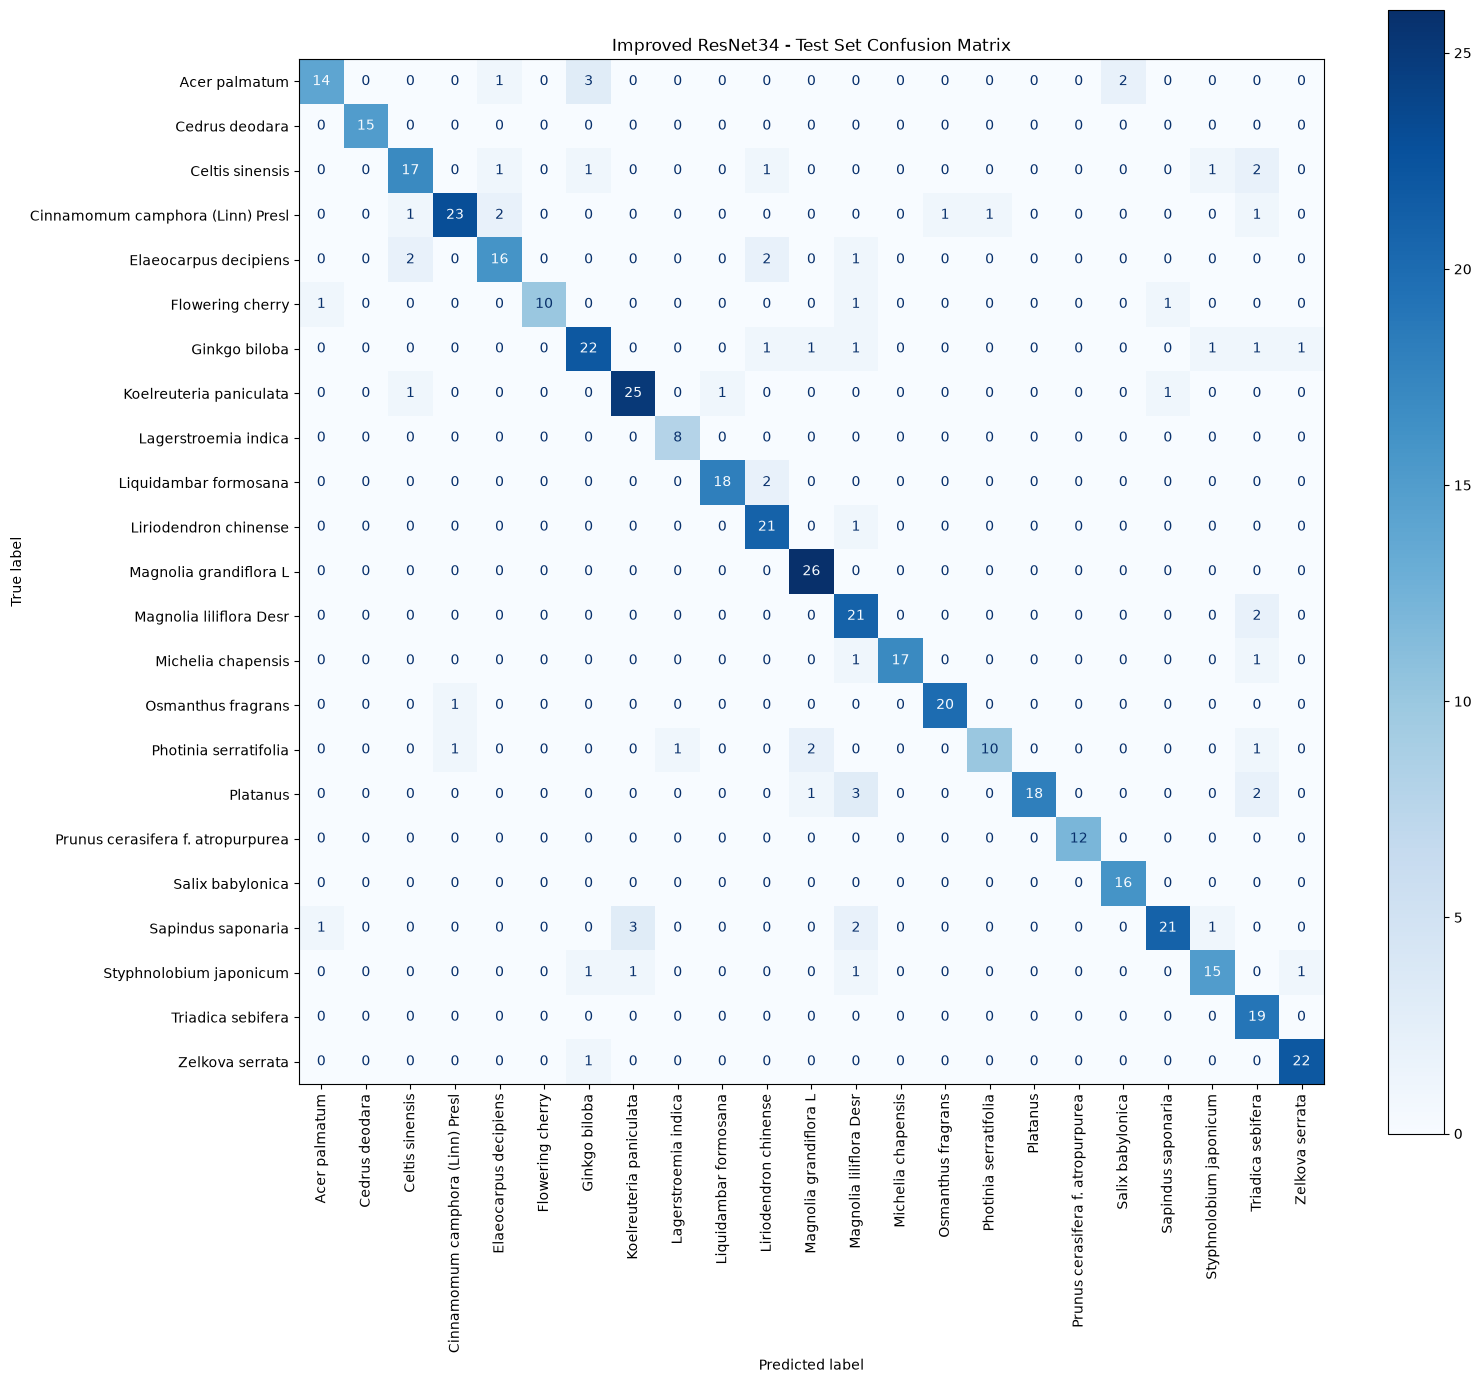

In [39]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_ft = confusion_matrix(y_true_ft, y_pred_ft)

fig, ax = plt.subplots(figsize=(16, 14))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_ft,
    display_labels=test_dataset.classes
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=True,
    values_format="d"
)

plt.title("Improved ResNet34 - Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

### Step 42 - Top-N accuracy for improved ResNet34

In [40]:
resnet34_ft.eval()

topn_correct_ft = {n: 0 for n in range(1, 6)}
topn_total_ft = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet34_ft(images)

        _, top5_predictions = outputs.topk(5, dim=1)

        for n in range(1, 6):
            correct_n = top5_predictions[:, :n].eq(
                labels.view(-1, 1)
            ).any(dim=1)

            topn_correct_ft[n] += correct_n.sum().item()

        topn_total_ft += labels.size(0)

for n in range(1, 6):
    accuracy = topn_correct_ft[n] / topn_total_ft
    print(
        f"Improved ResNet34 Top-{n} Accuracy: "
        f"{accuracy:.3f} ({accuracy * 100:.1f}%)"
    )

Improved ResNet34 Top-1 Accuracy: 0.860 (86.0%)
Improved ResNet34 Top-2 Accuracy: 0.924 (92.4%)
Improved ResNet34 Top-3 Accuracy: 0.943 (94.3%)
Improved ResNet34 Top-4 Accuracy: 0.958 (95.8%)
Improved ResNet34 Top-5 Accuracy: 0.968 (96.8%)


### Step 43 - Improved ResNet34 Results Summary

The pretrained ResNet34 was fully fine-tuned by allowing all model parameters to update during training. The model was trained for 25 epochs using SGD with momentum and a StepLR learning-rate scheduler.

The best validation accuracy was **90.2%**, achieved at epoch 18. The weights from the best validation epoch were restored before final testing.

On the independent test set, the improved ResNet34 achieved:

- **Accuracy:** 86.0% (406/472 correct)
- **Macro Precision:** 0.881
- **Macro Recall:** 0.868
- **Macro F1-score:** 0.868
- **Top-2 Accuracy:** 92.4%
- **Top-3 Accuracy:** 94.3%
- **Top-4 Accuracy:** 95.8%
- **Top-5 Accuracy:** 96.8%

Compared with the frozen ResNet34 baseline, test accuracy increased from **54.2% to 86.0%**, an improvement of **31.8 percentage points**. Macro F1-score also increased from **0.555 to 0.868**.

These results show that the full fine-tuning training strategy was substantially more effective than training only the final classification layer for this tree-species dataset. The Top-N results also show that the correct species was within the model's top two predictions for **92.4%** of the test images and within its top five predictions for **96.8%**.

### Step 44 - Final Model Comparison

The three model configurations were evaluated on the same independent test set. The comparison shows the effect of both model depth and training strategy.

| Metric | ResNet18 Frozen | ResNet34 Frozen | ResNet34 Fine-Tuned |
|---|---:|---:|---:|
| Best Validation Accuracy | 64.7% | 63.3% | **90.2%** |
| Test Accuracy | 55.9% | 54.2% | **86.0%** |
| Macro Precision | 0.617 | 0.589 | **0.881** |
| Macro Recall | 0.575 | 0.551 | **0.868** |
| Macro F1-score | 0.575 | 0.555 | **0.868** |
| Top-2 Accuracy | 68.6% | 66.9% | **92.4%** |
| Top-3 Accuracy | 76.9% | 75.6% | **94.3%** |
| Top-4 Accuracy | 82.2% | 80.7% | **95.8%** |
| Top-5 Accuracy | 85.0% | 85.0% | **96.8%** |

Under the frozen-feature setup, increasing the architecture depth from ResNet18 to ResNet34 did not improve performance. ResNet18 achieved 55.9% test accuracy, while ResNet34 achieved 54.2%.

The major improvement occurred when the ResNet34 pretrained layers were allowed to update during full fine-tuning. Test accuracy increased from **54.2% to 86.0%**, while macro F1-score increased from **0.555 to 0.868**.

This suggests that the **training strategy was more important than simply increasing model depth** in these experiments. The improved training strategy allowed the pretrained ImageNet features to adapt to the tree-species dataset and was associated with substantially better test performance.

The Top-N comparison also shows a substantial improvement. With the fine-tuned ResNet34, the correct species was among the top two predictions for **92.4%** of test images and among the top five predictions for **96.8%**.

### Step 45 - N-Best Performance Analysis

N-best accuracy evaluates whether the correct tree species appears within the model's highest-ranked predictions rather than considering only the Top-1 prediction.

#### Frozen ResNet18 vs Frozen ResNet34

| N | ResNet18 | ResNet34 |
|---|---:|---:|
| Top-1 | 55.9% | 54.2% |
| Top-2 | 68.6% | 66.9% |
| Top-3 | 76.9% | 75.6% |
| Top-4 | 82.2% | 80.7% |
| Top-5 | 85.0% | 85.0% |

The two frozen-feature models remain very close across the tested values of N. The difference is 1.7 percentage points at Top-1 and Top-2, 1.3 points at Top-3, 1.5 points at Top-4, and disappears at Top-5, where both models achieve 85.0%.

Therefore, within the investigated range of **N = 1 to 5, no value of N was found beyond which the performance of the frozen ResNet18 and ResNet34 models begins to separate clearly**. Instead, their N-best performance converges at Top-5.

#### Effect of ResNet34 Fine-Tuning

| N | ResNet18 Frozen | ResNet34 Frozen | ResNet34 Fine-Tuned |
|---|---:|---:|---:|
| Top-1 | 55.9% | 54.2% | **86.0%** |
| Top-2 | 68.6% | 66.9% | **92.4%** |
| Top-3 | 76.9% | 75.6% | **94.3%** |
| Top-4 | 82.2% | 80.7% | **95.8%** |
| Top-5 | 85.0% | 85.0% | **96.8%** |

The fine-tuned ResNet34 separates clearly from both frozen-feature models already at **Top-1**, and the advantage remains across all tested N values.

This indicates that increasing model depth alone did not create a meaningful performance separation under the frozen-feature training strategy. In contrast, allowing the pretrained ResNet34 features to adapt to the tree-species dataset produced a substantial improvement in both Top-1 and N-best classification performance.

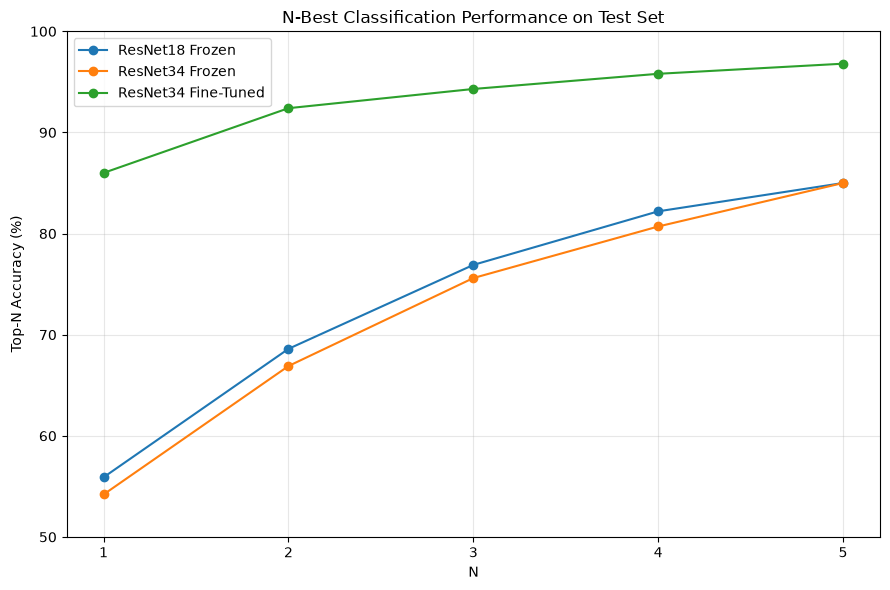

In [49]:
# Step 45 - Plot N-best classification performance

n_values = [1, 2, 3, 4, 5]

resnet18_frozen_topn = [55.9, 68.6, 76.9, 82.2, 85.0]
resnet34_frozen_topn = [54.2, 66.9, 75.6, 80.7, 85.0]
resnet34_finetuned_topn = [86.0, 92.4, 94.3, 95.8, 96.8]

plt.figure(figsize=(9, 6))

plt.plot(
    n_values,
    resnet18_frozen_topn,
    marker="o",
    label="ResNet18 Frozen"
)

plt.plot(
    n_values,
    resnet34_frozen_topn,
    marker="o",
    label="ResNet34 Frozen"
)

plt.plot(
    n_values,
    resnet34_finetuned_topn,
    marker="o",
    label="ResNet34 Fine-Tuned"
)

plt.xlabel("N")
plt.ylabel("Top-N Accuracy (%)")
plt.title("N-Best Classification Performance on Test Set")

plt.xticks(n_values)
plt.ylim(50, 100)
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

### Step 46 - Visual inspection of misclassified test images

In [47]:
# Find the misclassified images

from PIL import Image

resnet34_ft.eval()

misclassified = []

with torch.no_grad():
    for batch_idx, (images, labels) in enumerate(test_loader):
        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet34_ft(images)
        predictions = outputs.argmax(dim=1)

        for i in range(len(labels)):
            if labels[i] != predictions[i]:

                # test_loader uses shuffle=False
                dataset_idx = batch_idx * test_loader.batch_size + i
                image_path, _ = test_dataset.samples[dataset_idx]

                misclassified.append(
                    (
                        image_path,
                        labels[i].item(),
                        predictions[i].item()
                    )
                )

print("Total misclassified images:", len(misclassified))

Total misclassified images: 66


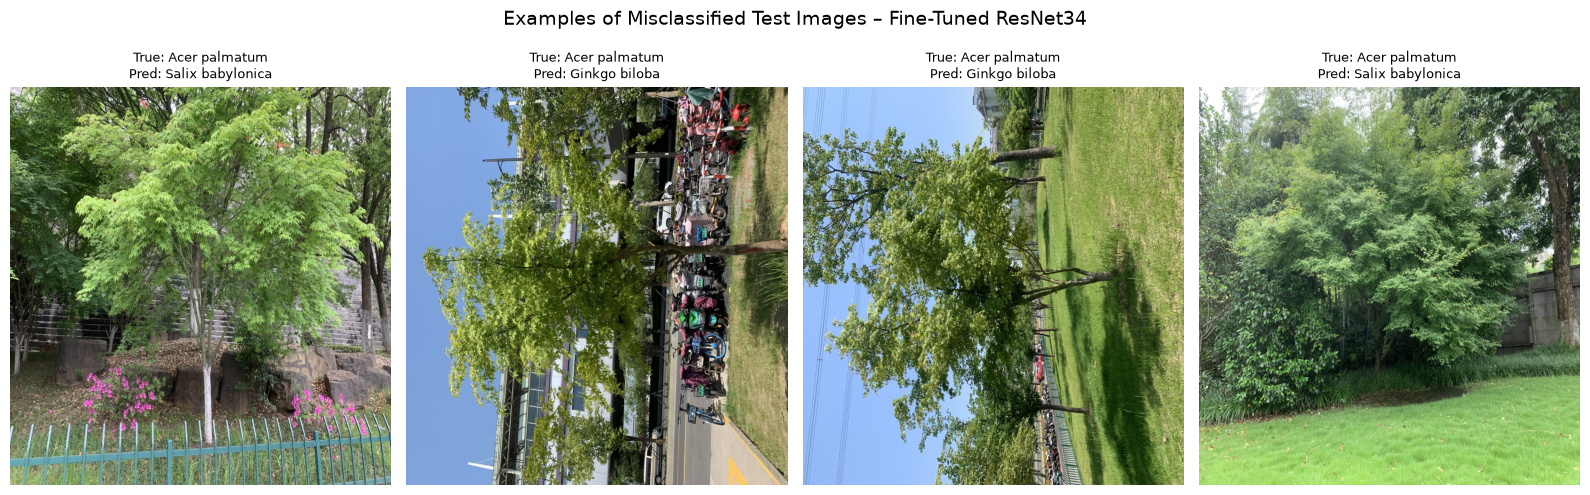

In [48]:
# Display examples of misclassified test images

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for ax, (image_path, true_idx, pred_idx) in zip(
    axes, misclassified[:4]
):
    image = Image.open(image_path).convert("RGB")

    ax.imshow(image, aspect="auto")

    true_name = test_dataset.classes[true_idx]
    pred_name = test_dataset.classes[pred_idx]

    ax.set_title(
        f"True: {true_name}\nPred: {pred_name}",
        fontsize=9
    )
    ax.axis("off")

plt.suptitle(
    "Examples of Misclassified Test Images – Fine-Tuned ResNet34",
    fontsize=14
)

plt.tight_layout()
plt.show()

### Visual Error Analysis

The fine-tuned ResNet34 misclassified 66 of the 472 test images. Visual inspection of several misclassified examples shows that some images are rotated, while others have a normal orientation. The examples also contain different viewpoints, backgrounds, tree sizes, and visually similar green foliage.

This suggests that orientation may contribute to some classification errors, but it is not the only source of difficulty. The remaining errors may also be influenced by variation in viewpoint and background, as well as visual similarities between tree species.

The baseline ResNet34 achieved 54.2% test accuracy with frozen pretrained features. After full fine-tuning, test accuracy increased to 86.0% and macro F1-score increased from 0.555 to 0.868. The confusion matrix also became substantially more diagonal.

These results show that the combined fine-tuning strategy was much more effective than keeping the pretrained feature extractor frozen. However, because several training choices changed together, including unfreezing the network and using SGD with a learning-rate scheduler, this experiment does not isolate the contribution of each individual change.

### Step 47 - Error Analysis and Improvement Discussion

The baseline experiments showed that simply using a deeper ResNet architecture did not improve classification performance. The frozen ResNet18 achieved 55.9% test accuracy, while the frozen ResNet34 achieved 54.2%.

The confusion matrices showed that both baseline models correctly classified some species well but confused several other species. The dataset exploration also showed several challenges that may contribute to these errors:

- The 23 classes are not perfectly balanced.
- Images contain different orientations and viewpoints.
- Trees appear at different scales and distances.
- Images contain complex urban backgrounds.
- Lighting and image appearance vary.
- Some tree species have visually similar characteristics.

To make the training data more varied while keeping the validation and test sets deterministic, the training pipeline used RandomResizedCrop, horizontal flipping, small rotations, and ColorJitter.

The main model improvement was changing ResNet34 from **frozen feature extraction** to **full fine-tuning**. Instead of updating only the final classification layer, all pretrained ResNet34 parameters were allowed to adapt to the tree-species dataset. SGD with momentum and a StepLR learning-rate scheduler were used during this training.

This produced a substantial improvement:

- **Best validation accuracy:** 63.3% → 90.2%
- **Test accuracy:** 54.2% → 86.0%
- **Macro F1-score:** 0.555 → 0.868
- **Top-5 accuracy:** 85.0% → 96.8%

The improved confusion matrix also contains a much stronger diagonal, showing that correct classifications increased across many species.

These results suggest that the baseline limitation was not simply the ResNet architecture itself. The improved training strategy allowed the pretrained ResNet34 features to adapt to the tree-species dataset and produced substantially better performance on the independent test set. Because several training choices changed together, the contribution of each individual change cannot be determined from this experiment alone.

Further improvement could include a more systematic analysis of misclassified test images, methods for addressing class imbalance, alternative augmentation settings, learning-rate experiments, and selective fine-tuning strategies. However, the current experiment already demonstrates a clear and measurable improvement over the baseline training strategy.